# Assignment 3

Hao YAN (hy2878)

Part 1 builds the GAN from `helper_lib/model.py` and checks the output size of each layer. 
Part 2 trains it on MNIST, saves the generator for the API, and shows generated digits.

Install these packages 

```python
%pip install torch torchvision matplotlib tqdm
```


In [1]:
#Applied GenAI
#Hao YAN hy2878

import sys
from pathlib import Path

import torch


for candidate in [Path.cwd(), Path.cwd().parent, Path.cwd().parent / "gentext-app"]:
    if (candidate / "pyproject.toml").is_file():
        PROJECT_DIR = candidate.resolve()
        break
else:
    raise RuntimeError("Run this notebook from the repository or its notebooks folder.")

# Make helper_lib importable from the notebook
sys.path.insert(0, str(PROJECT_DIR))

from helper_lib.model import get_model

## Part 1: GAN Architecture

In [2]:
gan = get_model("GAN")

print(gan.generator)
print(gan.discriminator)

Generator(
  (fc): Linear(in_features=100, out_features=6272, bias=True)
  (reshape): Unflatten(dim=1, unflattened_size=(128, 7, 7))
  (deconv1): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (act1): ReLU()
  (deconv2): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (tanh): Tanh()
)
Discriminator(
  (conv1): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (act1): LeakyReLU(negative_slope=0.2)
  (conv2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (act2): LeakyReLU(negative_slope=0.2)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc): Linear(in_features=6272, out_features=1, bias=True)
)


In [3]:
# Shape check, layer by layer
# The layers are defined in forward order, so running them one by one
# shows the output size after each step.
torch.manual_seed(42)
noise = torch.randn(4, 100)

with torch.no_grad():
    x = noise
    print("Generator")
    print(f"{'input':<10} {tuple(x.shape)}")
    for name, layer in gan.generator.named_children():
        x = layer(x)
        print(f"{name:<10} {tuple(x.shape)}")

    fake_images = x

    print()
    print("Discriminator")
    print(f"{'input':<10} {tuple(x.shape)}")
    for name, layer in gan.discriminator.named_children():
        x = layer(x)
        print(f"{name:<10} {tuple(x.shape)}")

    # Same result as calling the models directly
    assert torch.allclose(gan.generator(noise), fake_images)
    assert torch.allclose(gan.discriminator(fake_images), x)

assert fake_images.shape == (4, 1, 28, 28)
assert fake_images.min() >= -1 and fake_images.max() <= 1
assert x.shape == (4, 1)

print()
print("Shape check passed.")

Generator
input      (4, 100)
fc         (4, 6272)
reshape    (4, 128, 7, 7)
deconv1    (4, 64, 14, 14)
bn1        (4, 64, 14, 14)
act1       (4, 64, 14, 14)
deconv2    (4, 1, 28, 28)
tanh       (4, 1, 28, 28)

Discriminator
input      (4, 1, 28, 28)
conv1      (4, 64, 14, 14)
act1       (4, 64, 14, 14)
conv2      (4, 128, 7, 7)
bn2        (4, 128, 7, 7)
act2       (4, 128, 7, 7)
flatten    (4, 6272)
fc         (4, 1)

Shape check passed.


## Part 2: Training on MNIST

In [4]:
from torch import nn
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

from helper_lib.data_loader import get_data_loader
from helper_lib.trainer import train_gan
from helper_lib.generator import generate_samples

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Using device:", device)

Using device: mps


Training images: 60000
Image batch shape: torch.Size([128, 1, 28, 28])
Pixel range: -1.0 to 1.0


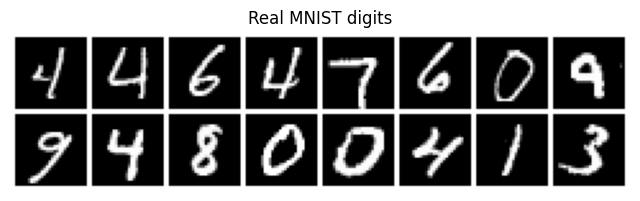

In [6]:
# MNIST is downloaded to data/ in the repository (ignored by git)
BATCH_SIZE = 128
train_loader = get_data_loader(PROJECT_DIR / "data", batch_size=BATCH_SIZE)

# Check the prepared data
batch_images, batch_labels = next(iter(train_loader))

print("Training images:", len(train_loader.dataset))
print("Image batch shape:", batch_images.shape)
print("Pixel range:", batch_images.min().item(), "to", batch_images.max().item())

# Show 16 real digits, undoing the [-1, 1] scaling for display
grid = make_grid((batch_images[:16] + 1) / 2, nrow=8, pad_value=1)

plt.figure(figsize=(8, 2.2))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.title("Real MNIST digits")
plt.show()

In [7]:
# Set the random seed for reproducibility
torch.manual_seed(42)

# Initialize the GAN defined in Part 1
gan = get_model("GAN").to(device)

criterion = nn.BCEWithLogitsLoss()

# Separate optimizers, with the Adam settings from the DCGAN paper
gen_optimizer = torch.optim.Adam(
    gan.generator.parameters(), lr=0.0002, betas=(0.5, 0.999)
)
disc_optimizer = torch.optim.Adam(
    gan.discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999)
)

EPOCHS = 20

gan = train_gan(
    gan,
    train_loader,
    criterion,
    (gen_optimizer, disc_optimizer),
    device=device,
    epochs=EPOCHS
)

print("Training finished.")

Epoch 1/20: 100%|██████████| 469/469 [00:10<00:00, 44.19it/s]


D loss: 0.3825 | G loss: 2.2217


Epoch 2/20: 100%|██████████| 469/469 [00:10<00:00, 45.36it/s]


D loss: 0.3541 | G loss: 2.4381


Epoch 3/20: 100%|██████████| 469/469 [00:10<00:00, 44.95it/s]


...

D loss: 0.3198 | G loss: 3.1819


Epoch 19/20: 100%|██████████| 469/469 [00:10<00:00, 45.39it/s]


D loss: 0.2269 | G loss: 3.4092


Epoch 20/20: 100%|██████████| 469/469 [00:10<00:00, 46.06it/s]

D loss: 0.2445 | G loss: 3.4731
Training finished.


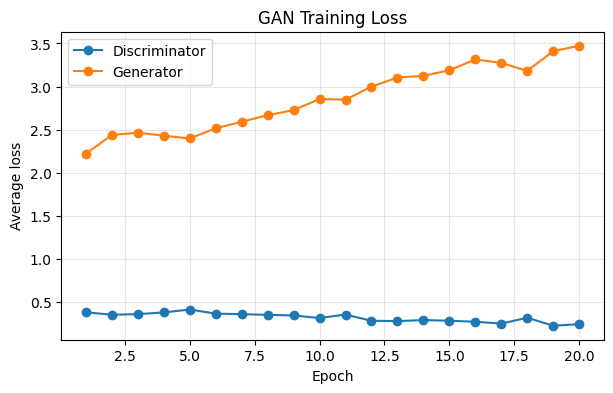

In [8]:
plt.figure(figsize=(7, 4))

plt.plot(
    range(1, EPOCHS + 1),
    gan.history["d_loss"],
    marker="o",
    label="Discriminator"
)
plt.plot(
    range(1, EPOCHS + 1),
    gan.history["g_loss"],
    marker="o",
    label="Generator"
)

plt.xlabel("Epoch")
plt.ylabel("Average loss")
plt.title("GAN Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

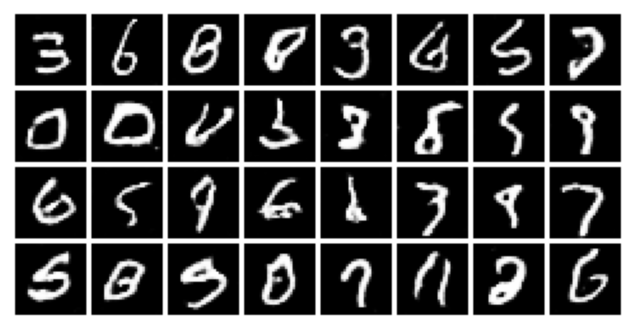

In [9]:
# Generate 32 new digits from random noise
generate_samples(gan, device, num_samples=32)

In [10]:
MODEL_DIR = PROJECT_DIR / "app" / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "mnist_gan_generator.pth"

# The API only needs the generator to create new images
checkpoint = {
    "generator_state_dict": {
        name: tensor.detach().cpu()
        for name, tensor in gan.generator.state_dict().items()
    },
    "z_dim": gan.z_dim,
    "image_size": [28, 28],
    "preprocessing": "ToTensor() + Normalize((0.5,), (0.5,))",
    "epochs": EPOCHS,
    "final_d_loss": gan.history["d_loss"][-1],
    "final_g_loss": gan.history["g_loss"][-1]
}

torch.save(checkpoint, MODEL_PATH)

print("Model saved to:", MODEL_PATH.relative_to(PROJECT_DIR))
print(f"File size: {MODEL_PATH.stat().st_size / 1024**2:.2f} MB")

Model saved to: app/models/mnist_gan_generator.pth
File size: 2.93 MB
